# White dwarf binary merger rates and the Galactic DWD population

Python port of **Lucy McNeill's** Mathematica notebook `paper-calculations.nb`.
All physics, numbers and section structure follow the original; credit for the analysis belongs to Lucy McNeill.

Section numbers match the original notebook. Re-usable functions live in the `galactic_foreground` package (`src/`).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import matplotlib.pyplot as plt
from galactic_foreground import data, selection, population, stability, gw
from galactic_foreground.constants import HE_CO_SPLIT, NELEMANS_FIT

plt.rcParams.update({"font.family": "serif", "font.size": 13, "axes.grid": True, "grid.alpha": 0.3})

## Section 2 (Motivation): the sample from Cheng et al. 2020

From the caption of Fig. 3 in Cheng+2020, the number of merger remnants per mass bin:
408 (0.07), 431 (0.15), 323 (0.27), 176 (0.35), 57 (0.18) = 29, 65, 87, 62, 10.

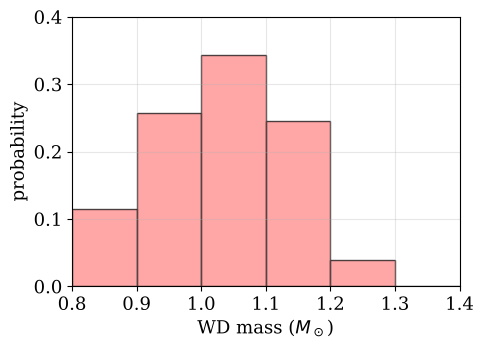

In [2]:
cheng = data.cheng2020_sample()
CHENG_BINS = np.arange(0.8, 1.41, 0.1)

def cheng_hist(ax):
    ax.hist(cheng, bins=CHENG_BINS, weights=np.full(cheng.size, 1 / cheng.size),
            color="#ff8080", alpha=0.7, edgecolor="k", label="Cheng+2020")

fig, ax = plt.subplots(figsize=(5, 3.5))
cheng_hist(ax)
ax.set(xlabel=r"WD mass ($M_\odot$)", ylabel="probability", xlim=(0.8, 1.4), ylim=(0, 0.4));

## Section 3.1/3.2 (Results): an intrinsic mass distribution for WDs in double white dwarf binaries

Sample of WDs in binaries collated by James Munday (https://github.com/JamesMunday98/CloseDWDbinaries).
We want an intrinsic mass distribution $N_{\rm MW}(m)$ of WDs in short-period binaries (potential merger progenitors).
From the observed, roughly magnitude-limited $N_{\rm obs}(m)$ we deform according to how much harder (easier) it is to see
higher (lower) mass WDs at fixed surface temperature. Only binaries with both $m_1$ and $m_2$ constrained and at least one temperature are kept.

`load_sample` uses `data/munday-cut-4.csv` (the original cut) if present; otherwise it rebuilds the cut from the public catalogue (see `data/README.md`).

In [3]:
sample, source = data.load_sample(ROOT / "data")
print("source:", source)
print("binaries:", sample["m1"].size, "| measured T2:", int(np.sum(sample["T2"] > -50)))

source: /home/user/MBresponse/galactic-foreground-generator/data/CloseDoubleWhiteDwarfs_20261109.csv
binaries: 141 | measured T2: 75


Observed mass distribution of all components, and of those that also have a measured temperature (blue):

216 WDs with both mass and temperature


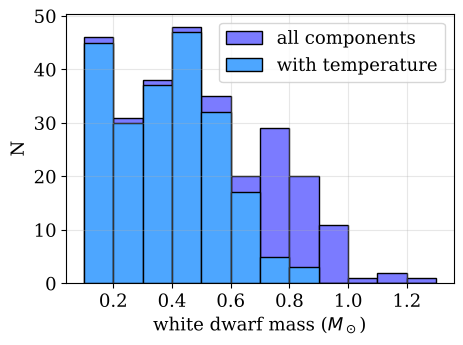

In [4]:
all_masses = np.concatenate([sample["m1"], sample["m2"]])
blue_mass, blue_temp = data.masses_with_temperatures(sample)
print(f"{blue_mass.size} WDs with both mass and temperature")

MBINS = np.arange(0.1, 1.31, 0.1)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.hist(all_masses, bins=MBINS, color="#7b7bff", edgecolor="k", label="all components")
ax.hist(blue_mass, bins=MBINS, color="#4da6ff", edgecolor="k", label="with temperature")
ax.set(xlabel=r"white dwarf mass ($M_\odot$)", ylabel="N"); ax.legend();

### Selection function

Analytic radius fits ($R_\odot$; $T$ in $10^4$ K) for He- and CO-core WDs:

$R_{\rm He} = 0.0132\,10^{-0.177 T^{1/2}}\,m^{0.148-0.941T^{1/2}}$, $\quad R_{\rm CO} = 0.009\,10^{-0.00063T^2}\,m^{-0.5-0.13T}$.

Masses < 0.45 $M_\odot$ are treated as He-core, ≥ 0.45 as CO-core.

* Step 1/2: down-weight exceptionally hot WDs by $L_{\rm ref}/L$, where $L_{\rm ref}$ uses the sample's mean (He) temperature in the radius.
* Step 2/2: repeat each mass by how much harder/easier it is to see than the reference WD (mean He mass and temperature).

reference temperature = 1.35112 x 1e4 K, reference mass = 0.28029 Msun


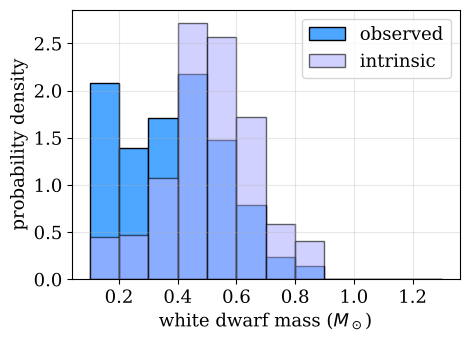

In [5]:
repeats, ref_mass, ref_temp4 = selection.selection_repeats(blue_mass, blue_temp)
print(f"reference temperature = {ref_temp4:.5f} x 1e4 K, reference mass = {ref_mass:.5f} Msun")
intrinsic = selection.intrinsic_masses(blue_mass, blue_temp)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.hist(blue_mass, bins=MBINS, density=True, color="#4da6ff", edgecolor="k", label="observed")
ax.hist(intrinsic, bins=MBINS, density=True, color="#b3b3ff", alpha=0.6, edgecolor="k", label="intrinsic")
ax.set(xlabel=r"white dwarf mass ($M_\odot$)", ylabel="probability density"); ax.legend();

Original notebook: reference temperature 1.35209, reference mass 0.27748 (Feb-2026 cut).

### Sampling $m_1$ and $m_2$ from this distribution

Pairs are drawn independently from a histogram distribution of the intrinsic masses
(the original used Mathematica's automatic `HistogramDistribution` binning and an unseeded RNG; here bin width 0.05 $M_\odot$ and a fixed seed).

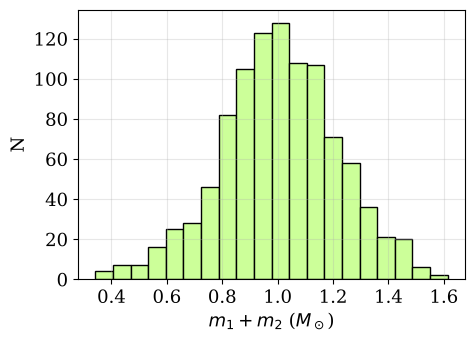

In [6]:
N_WD = 1000
m1M, m2M = population.draw_pairs(intrinsic, n=N_WD, seed=42)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.hist(m1M + m2M, bins=20, color="#ccff99", edgecolor="k")
ax.set(xlabel=r"$m_1+m_2$ ($M_\odot$)", ylabel="N");

### Separating in terms of composition

Cheng's sample should not include He+He mergers, so these are excluded from the sums. $m_1$ is the more massive component.

In [7]:
comp = population.composition(m1M, m2M)
no_hehe = (m1M + m2M)[~comp["HeHe"]]
for k, v in comp.items():
    print(f"{k}: {v.mean():.3f}")
print("original notebook: HeHe 0.08, HeCO 0.40, COCO 0.52")

HeHe: 0.128
HeCO: 0.451
COCO: 0.421
original notebook: HeHe 0.08, HeCO 0.40, COCO 0.52


## Section 3.3 (Results): comparison with Cheng et al. 2020

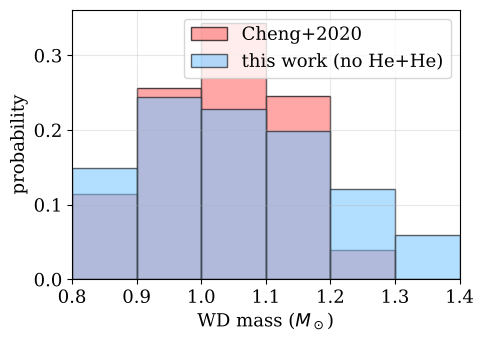

In [8]:
sel = no_hehe[(no_hehe > 0.8) & (no_hehe < 1.4)]
fig, ax = plt.subplots(figsize=(5, 3.5))
cheng_hist(ax)
ax.hist(sel, bins=CHENG_BINS, weights=np.full(sel.size, 1 / sel.size),
        color="#80c8ff", alpha=0.6, edgecolor="k", label="this work (no He+He)")
ax.set(xlabel=r"WD mass ($M_\odot$)", ylabel="probability", xlim=(0.8, 1.4)); ax.legend();

## Section 4: pairings for $m_1$ and $m_2$

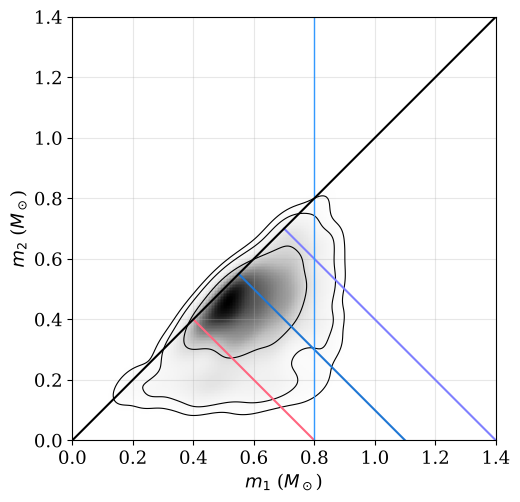

In [9]:
X, Y, Z, levels = population.kde_with_hpd_levels(m1M, m2M)
x = np.linspace(0, 1.4, 200)

def corner(ax):
    ax.pcolormesh(X, Y, Z, cmap="Greys", shading="auto")
    ax.contour(X, Y, Z, levels=sorted(levels), colors="k", linewidths=0.8)
    ax.plot([0.4, 0.8], [0.4, 0.0], color="#ff6680", label="0.8 (ultra)")
    ax.plot([0.55, 1.1], [0.55, 0.0], color="#1f77d4", label="1.1 (sub-Chandra)")
    ax.plot([0.7, 1.4], [0.7, 0.0], color="#8080ff", label="1.4 (Chandrasekhar)")
    ax.axvline(0.8, color="#3399ff", lw=1)
    ax.plot(x, x, "k")
    ax.set(xlim=(0, 1.4), ylim=(0, 1.4), aspect="equal", xlabel=r"$m_1$ ($M_\odot$)", ylabel=r"$m_2$ ($M_\odot$)")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
corner(ax);

### Separations into total mass sum

In [10]:
for k, v in population.mass_sum_fractions(m1M, m2M).items():
    print(f"{k:24s} {v:.3f}")
print("original notebook: >1.4 0.081, <0.8 0.15, 0.8-1.4 0.769, 1.1-1.4 0.303, 0.8-1.1 0.466")

super_chandra (>1.4)     0.035
elm_merger (<0.8)        0.145
sub_chandra (0.8-1.4)    0.820
0.8-1.1                  0.522
1.1-1.4                  0.298
original notebook: >1.4 0.081, <0.8 0.15, 0.8-1.4 0.769, 1.1-1.4 0.303, 0.8-1.1 0.466


### Some definitions: stable vs unstable mass transfer

Eggleton's zero-temperature mass–radius relation (Verbunt & Rappaport 1988); Roche-lobe derivative from Eggleton (1983);
polytropic donor response $\zeta_2 = -1/3$ (Soberman et al. 1997); GW angular momentum loss.
The boundary is where the mass-transfer rate equals the Eddington-like limit of the accretor.

refit:          m2 = -0.2099 + 0.5248 m1^(1/4)
notebook (used): m2 = -0.1787 + 0.4907 m1^(1/4)


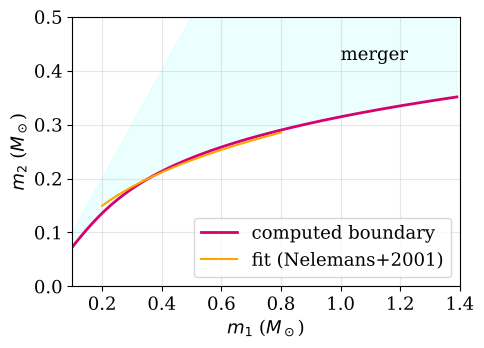

In [11]:
m1_grid, m2_boundary = stability.boundary_curve()
a_fit, b_fit = stability.fit_quarter_power(m1_grid, m2_boundary)
print(f"refit:          m2 = {a_fit:.4f} + {b_fit:.4f} m1^(1/4)")
print(f"notebook (used): m2 = {NELEMANS_FIT[0]:.4f} + {NELEMANS_FIT[1]:.4f} m1^(1/4)")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(m1_grid, m2_boundary, color="#d6006e", lw=2, label="computed boundary")
mm = np.linspace(0.2, 0.8, 100)
ax.plot(mm, population.nelemans_boundary(mm), color="orange", label="fit (Nelemans+2001)")
ax.fill_between(m1_grid, m2_boundary, m1_grid, where=m1_grid > m2_boundary, color="cyan", alpha=0.08)
ax.text(1.0, 0.42, "merger")
ax.set(xlim=(0.1, 1.4), ylim=(0, 0.5), xlabel=r"$m_1$ ($M_\odot$)", ylabel=r"$m_2$ ($M_\odot$)"); ax.legend();

The refit coefficients differ from the notebook's because Mathematica's `FindRoot` did not converge for very small $m_1$ (warnings in the original)
and those points entered its fit. The two curves agree to ≲0.01 $M_\odot$ over $0.2 < m_1 < 1.4$. Downstream counts use the notebook's coefficients.

### Unstable vs stable

In [12]:
s = m1M + m2M
for label, mask in [("0.8-1.4", (s > 0.8) & (s < 1.4)), ("<0.8", s < 0.8), ("all", np.ones_like(s, bool))]:
    unstable, stable = population.stable_fraction(m1M[mask], m2M[mask])
    print(f"{label:8s} unstable {unstable:4d}  stable {stable:4d}  stable fraction {stable / (stable + unstable):.2f}")
print("original notebook: 0.8-1.4 730/39, <0.8 75/75, all 886/114 (~10% stable)")

0.8-1.4  unstable  789  stable   31  stable fraction 0.04
<0.8     unstable   78  stable   67  stable fraction 0.46
all      unstable  902  stable   98  stable fraction 0.10
original notebook: 0.8-1.4 730/39, <0.8 75/75, all 886/114 (~10% stable)


### Figure 2

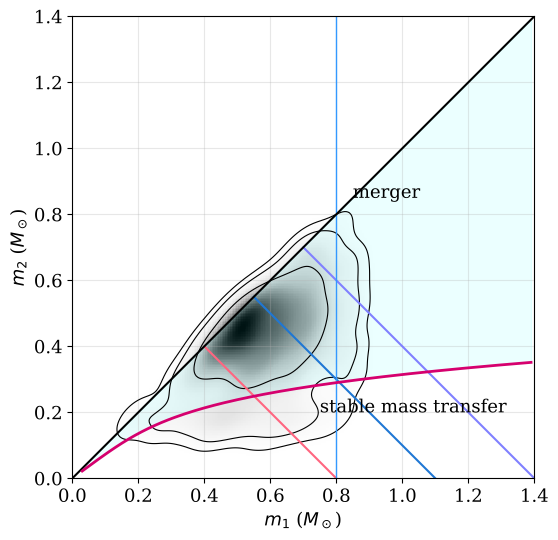

In [13]:
fig, ax = plt.subplots(figsize=(6, 6))
corner(ax)
ax.plot(m1_grid, m2_boundary, color="#d6006e", lw=2)
ax.fill_between(m1_grid, m2_boundary, m1_grid, where=m1_grid > m2_boundary, color="cyan", alpha=0.08)
ax.text(0.85, 0.85, "merger"); ax.text(0.75, 0.2, "stable mass transfer")
fig.savefig(ROOT / "notebooks" / "figure2.png", dpi=150, bbox_inches="tight");

## Section 3: predictions for the types of binaries in the 100 pc sample (and Galaxy) (Fig. 4)

About 100 WD binaries in the Munday sample have periods < 333 min (0.1 mHz, possible Hubble-time mergers), within 1–2 kpc.
As in McNeill & Hirai (2025), focusing on the eclipsing shorter-period ones (where selection effects are minor) gives a lower bound
on the merger rate of DWDs containing a He component. We compare the predicted intrinsic population with what is observed and estimate
how many Hubble-time Ia progenitors hide in the 100 pc sample, and compare to population synthesis (Lamberts+2019).

Chirp mass $\mathcal{M} = (m_1 m_2)^{3/5}/(m_1+m_2)^{1/5}$:

HeHe       Mchirp = 0.261165
HeCO       Mchirp = 0.416724
COCO       Mchirp = 0.522330
COCO (Ia)  Mchirp = 0.601893


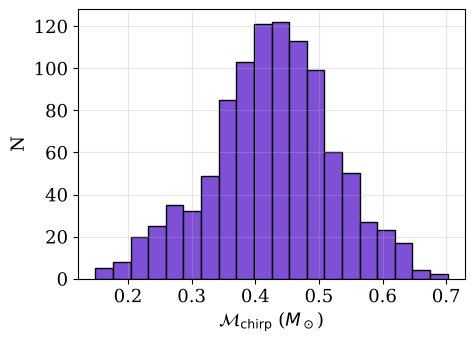

In [14]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.hist(gw.chirp_mass(m1M, m2M), bins=20, color="#7f4fd6", edgecolor="k")
ax.set(xlabel=r"$\mathcal{M}_{\rm chirp}$ ($M_\odot$)", ylabel="N")
for name, pair in {"HeHe": (0.3, 0.3), "HeCO": (0.3, 0.8), "COCO": (0.6, 0.6), "COCO (Ia)": (0.6, 0.8)}.items():
    print(f"{name:10s} Mchirp = {gw.chirp_mass(*pair):.6f}")

For fixed rate, the number scales as $\mathcal{M}^{-5/3}$: lower-mass binaries linger longer, so CO+CO are a few times less frequent than He+He
at given frequency for the same merger rate, broadly consistent with population synthesis.

Cheng+2020 found a rate of ~0.002/yr for mergers summing to 1.1–1.4 $M_\odot$; we predict this is underestimated by at least half:
1.1–1.4 → 0.004/yr; 0.8–1.1 → 0.004/yr; He+He ≈ 0.002/yr; super-Chandrasekhar CO+CO 0.001/yr.
Stable mass transfer is predicted ~10% of the time for He+CO and half the time for He+He.

Now the intrinsic numbers. $\dot f = \frac{96}{5}\pi^{8/3}(G\mathcal{M})^{5/3}f^{11/3}/c^5$:

In [15]:
print(f"df/dt = {gw.dfdt(1.0, 1.0):.5e} f^(11/3) Mchirp^(5/3)")
print(f"int_fmin^inf (df/dt)^-1 df (Mchirp=0.5) = {gw.time_to_merger(1.0, 0.5):.5e} fmin^(-8/3)")
fmin = gw.fmin_steady_state()
print(f"fmin for 1 Gyr steady state = {fmin:.6e} Hz  (orbital period {2 / fmin / 3600:.1f} h)")

df/dt = 5.82578e-07 f^(11/3) Mchirp^(5/3)
int_fmin^inf (df/dt)^-1 df (Mchirp=0.5) = 2.04359e+06 fmin^(-8/3)
fmin for 1 Gyr steady state = 1.513444e-04 Hz  (orbital period 3.7 h)


Rates per composition (He+He 7% → 0.0005/yr, He+CO 39% → 0.003/yr, CO+CO 54% → 0.003/yr). The cumulative number above frequency $f$ (mHz)
is $N(>f) = A\,f^{-8/3}$:

In [16]:
RATES = {"HeHe": (0.0005, gw.chirp_mass(0.3, 0.3)),
         "HeCO": (0.003, gw.chirp_mass(0.3, 0.8)),
         "COCO": (0.003, gw.chirp_mass(0.6, 0.6))}
coef = {k: gw.cumulative_coefficient(r, m) for k, (r, m) in RATES.items()}
coef["Sum"] = gw.cumulative_coefficient(sum(r for r, _ in RATES.values()), gw.chirp_mass(0.6, 0.6))  # as in original
for k, v in coef.items():
    print(f"{k:5s} A = {v:10.2f}")

HeHe  A =    9600.75
HeCO  A =   26438.37
COCO  A =   18144.27
Sum   A =   39312.59


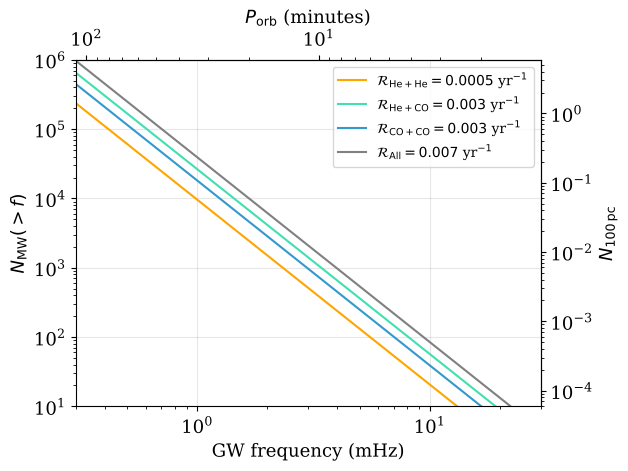

In [17]:
v100 = gw.volume_fraction_100pc()
f = np.logspace(np.log10(0.3), np.log10(30), 200)
styles = {"HeHe": ("orange", r"$\mathcal{R}_{\rm He+He}=0.0005$ yr$^{-1}$"),
          "HeCO": ("#40e0b0", r"$\mathcal{R}_{\rm He+CO}=0.003$ yr$^{-1}$"),
          "COCO": ("#3399cc", r"$\mathcal{R}_{\rm CO+CO}=0.003$ yr$^{-1}$"),
          "Sum":  ("grey",   r"$\mathcal{R}_{\rm All}=0.007$ yr$^{-1}$")}
fig, ax = plt.subplots(figsize=(6, 4.5))
for k, (c, lab) in styles.items():
    ax.loglog(f, coef[k] * f ** (-8 / 3), color=c, label=lab)
ax.set(xlim=(0.3, 30), ylim=(10, 1e6), xlabel="GW frequency (mHz)", ylabel=r"$N_{\rm MW}(>f)$")
top = ax.secondary_xaxis("top", functions=(lambda f: 2 / (np.maximum(f, 1e-9) * 1e-3) / 60,
                                           lambda p: 2 / (np.maximum(p, 1e-9) * 60) * 1e3))
top.set_xlabel(r"$P_{\rm orb}$ (minutes)")
right = ax.secondary_yaxis("right", functions=(lambda n: n * v100, lambda n: n / v100))
right.set_ylabel(r"$N_{\rm 100\,pc}$")
ax.legend(fontsize=10)
fig.savefig(ROOT / "notebooks" / "figure4.png", dpi=150, bbox_inches="tight");

These curves match the population synthesis of Lamberts+2019 (Fig. 7) within a factor of 2.
(The original's secondary-axis ticks were placeholders; here they are exact conversions: $P_{\rm orb}=2/f_{\rm GW}$ and $N_{100\,\rm pc}=N_{\rm MW}\,V_{100\,\rm pc}/V_{\rm MW}$.)

Now the 100 pc sample (5–10 such binaries within 100 pc in the Munday sample). Milky Way disc volume $\pi\,15^2\times1$ kpc³:

V_MW = 706.858 kpc^3, V_100pc = 0.004189 kpc^3, ratio = 5.92593e-06


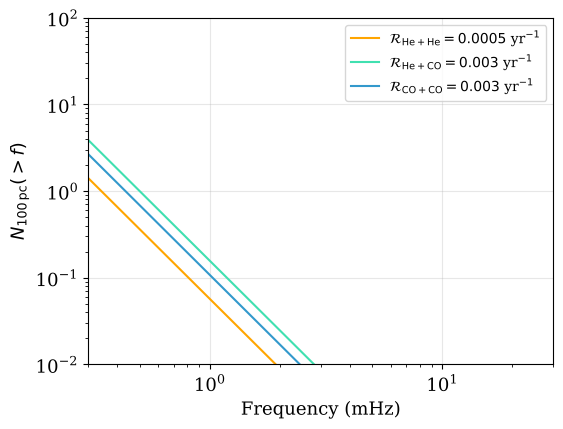

In [18]:
print(f"V_MW = {np.pi * 15**2:.3f} kpc^3, V_100pc = {4 / 3 * np.pi * 0.1**3:.6f} kpc^3, ratio = {v100:.5e}")
fig, ax = plt.subplots(figsize=(6, 4.5))
for k in ("HeHe", "HeCO", "COCO"):
    c, lab = styles[k]
    ax.loglog(f, v100 * coef[k] * f ** (-8 / 3), color=c, label=lab)
ax.set(xlim=(0.3, 30), ylim=(0.01, 100), xlabel="Frequency (mHz)", ylabel=r"$N_{\rm 100\,pc}(>f)$"); ax.legend(fontsize=10);

Number of He+He in the Milky Way at short orbital period, and the numbers within 100 pc:

In [19]:
n_hehe_mw = gw.number_in_band(0.0005, gw.chirp_mass(0.3, 0.3), 2e-4, 0.5)
print(f"N_HeHe (MW, 0.2-500 mHz) = {n_hehe_mw:,.0f}")
total = 0
for k, (r, m) in RATES.items():
    n = gw.number_in_band(r, m, 1.5e-4, 0.5, v100)
    total += n
    print(f"N_{k} (100 pc) = {n:.3f}")
print(f"total = {total:.1f}")

N_HeHe (MW, 0.2-500 mHz) = 701,819
N_HeHe (100 pc) = 8.957
N_HeCO (100 pc) = 24.665
N_COCO (100 pc) = 16.927
total = 50.5


So we estimate ~50 binaries with merger times < 1 Gyr in the 100 pc sample. Torres predicts ~1% of the 100 pc sample (~10,000 WDs)
are unresolved binaries, so this is of order 1% too (0.7%).

---
*Original analysis and Mathematica notebook: Lucy McNeill. Python port: this repository.*